In [ ]:
"""
================================================================================
CELL 0 — PACKAGE IMPORTS / INSTALLS
Run this first, before Cell 1 (data) and Cell 2 (Q6 model).
torch/pandas/numpy/scikit-learn are already present on Colab/Kaggle by default
-- only pennylane (quantum circuit correctness verification) and kagglehub
(dataset download) typically need installing.
================================================================================
"""

import subprocess, sys

def pip_install(*pkgs):
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
    except subprocess.CalledProcessError:
        # some environments (externally-managed Python) refuse a bare install -- retry with the override.
        # Harmless on Colab/Kaggle, where this branch is never needed.
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--break-system-packages", *pkgs], check=True)

pip_install("pennylane", "kagglehub")

# sanity import check -- fails loudly here rather than mid-run later
import math, os, glob, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pennylane as qml
import kagglehub

print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
print("pennylane:", qml.__version__)
print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("All packages imported OK.")

torch: 2.11.0+cpu | cuda available: False
pennylane: 0.45.1
pandas: 2.2.3 | numpy: 2.1.3
All packages imported OK.


In [ ]:
"""
================================================================================
CELL 1 — DATA ACQUISITION + PROCESSING
Same methodology as all prior cells (Kaggle download, phi-unit detection,
target construction, standardization, graph construction) with ONE change:
SPLIT is now 20% train / 20% val / 60% test -- the 60% that was previously
discarded as "unused" is now the test set instead. Nothing is thrown away.
================================================================================
"""

import os, math, glob, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

# ==============================================================================
# 0. CONFIGURATION  (unchanged from all prior cells)
# ==============================================================================
SEED = 42
USE_PT_FLOOR = True
PHI_UNITS = "auto"

KAGGLE_DATASET = "prateekagnihotri/cms-trigger-dataset"
LOCAL_FALLBACK_DIR = "/content"

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

N_NODES = 4
N_FEATS = 7
D_NODE = 4
N_QUBITS = 4
N_EDGES = N_NODES * (N_NODES - 1)
QDIM = 2 ** N_QUBITS
assert D_NODE == N_QUBITS

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# ==============================================================================
# 1. DATA ACQUISITION  (unchanged)
# ==============================================================================
STATIONS = [0, 2, 3, 4]
STATION_FEATS = ["Phi", "Theta", "BendingAngle", "TimeInfo", "RingNumber", "Front", "Mask"]
REQUIRED_STATION_COLS = [f"{feat}_{st}" for st in STATIONS for feat in STATION_FEATS]
REQUIRED_COLS = REQUIRED_STATION_COLS + ["q/pt"]

def find_csv_with_required_columns(root_dir, required_cols, max_files=200):
    for path in glob.glob(os.path.join(root_dir, "**", "*.csv"), recursive=True)[:max_files]:
        try:
            header = pd.read_csv(path, nrows=0).columns.tolist()
            if all(c in header for c in required_cols):
                return path
        except Exception:
            continue
    return None

def download_dataset():
    try:
        import kagglehub
        path = kagglehub.dataset_download(KAGGLE_DATASET)
        print("kagglehub download path:", path)
        found = find_csv_with_required_columns(path, REQUIRED_COLS)
        if found:
            return found
        any_csv = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
        if any_csv:
            return any_csv[0]
    except Exception as e:
        print("kagglehub path unavailable or failed:", repr(e))
    try:
        import kaggle
        dl_dir = "/content/cms_trigger_dataset"
        os.makedirs(dl_dir, exist_ok=True)
        kaggle.api.dataset_download_files(KAGGLE_DATASET, path=dl_dir, unzip=True)
        found = find_csv_with_required_columns(dl_dir, REQUIRED_COLS)
        if found:
            return found
    except Exception as e:
        print("kaggle API path unavailable or failed:", repr(e))
    found = find_csv_with_required_columns(LOCAL_FALLBACK_DIR, REQUIRED_COLS)
    if found:
        return found
    raise FileNotFoundError(f"Could not locate {KAGGLE_DATASET} CSV automatically.")

csv_path = download_dataset()
print("Discovered CSV file:", csv_path)
df_raw = pd.read_csv(csv_path)
missing = [c for c in REQUIRED_COLS if c not in df_raw.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")
print("Original dataset size:", len(df_raw))

# ==============================================================================
# 2. PHI UNIT DETECTION + TARGET CONSTRUCTION  (unchanged)
# ==============================================================================
_phi_cols = [f"Phi_{st}" for st in STATIONS]
_phi_vals = pd.to_numeric(df_raw[_phi_cols].stack(), errors="coerce")
_phi_vals = _phi_vals[np.isfinite(_phi_vals)]
_phi_span = float(_phi_vals.max() - _phi_vals.min())
if PHI_UNITS == "auto":
    PHI_IS_RADIANS = _phi_span <= 2 * math.pi + 1e-6
elif PHI_UNITS == "radians":
    PHI_IS_RADIANS = True
else:
    PHI_IS_RADIANS = False
print("Phi treated as:", "radians (wrapped)" if PHI_IS_RADIANS else "integer bins (plain diff)")

df = df_raw.copy()
with np.errstate(divide="ignore", invalid="ignore"):
    df["pT"] = np.abs(1.0 / df["q/pt"])

invalid_mask = (
    df["pT"].isna() | np.isinf(df["pT"]) | (df["pT"] <= 0)
    | df[REQUIRED_STATION_COLS].isna().any(axis=1)
    | np.isinf(df[REQUIRED_STATION_COLS]).any(axis=1)
)
df = df.loc[~invalid_mask].reset_index(drop=True)
print("Remaining rows after cleaning:", len(df))

# ==============================================================================
# 3. SPLIT — CHANGED: 20% train / 20% val / 60% test, nothing discarded
# ==============================================================================
N_total = len(df)
train_df, _rest1 = train_test_split(df, train_size=0.20, random_state=SEED, shuffle=True)
val_df, test_df = train_test_split(_rest1, train_size=0.25, random_state=SEED, shuffle=True)
# _rest1 is 80% of total; 0.25 of that = 20% of total -> val. The remaining 75% of
# _rest1 (=60% of total) is test_df in full -- no further split, no unused portion.
print(f"Total rows: {N_total} | Train: {len(train_df)} ({100*len(train_df)/N_total:.1f}%) "
      f"| Val: {len(val_df)} ({100*len(val_df)/N_total:.1f}%) "
      f"| Test: {len(test_df)} ({100*len(test_df)/N_total:.1f}%)")
assert len(train_df) + len(val_df) + len(test_df) == N_total, "split must cover the full dataset now"

# ==============================================================================
# 4. PREPROCESSING  (unchanged)
# ==============================================================================
def station_cols(st):
    return [f"{feat}_{st}" for feat in STATION_FEATS]

def build_X(d):
    return np.stack([d[station_cols(st)].values for st in STATIONS], axis=1).astype(np.float32)

X_train_raw = build_X(train_df)
X_val_raw   = build_X(val_df)
X_test_raw  = build_X(test_df)

X_mu = X_train_raw.mean(axis=0, keepdims=True)
X_sigma = np.maximum(X_train_raw.std(axis=0, keepdims=True), 1e-6)

def standardize(x):
    return (x - X_mu) / X_sigma

X_train, X_val, X_test = standardize(X_train_raw), standardize(X_val_raw), standardize(X_test_raw)

PHI_IDX = STATION_FEATS.index("Phi")
BA_IDX = STATION_FEATS.index("BendingAngle")
phi_train, ba_train = X_train_raw[:, :, PHI_IDX], X_train_raw[:, :, BA_IDX]
phi_val, ba_val     = X_val_raw[:, :, PHI_IDX], X_val_raw[:, :, BA_IDX]
phi_test, ba_test   = X_test_raw[:, :, PHI_IDX], X_test_raw[:, :, BA_IDX]

y_train = np.log1p(train_df["pT"].values.astype(np.float32))
y_val   = np.log1p(val_df["pT"].values.astype(np.float32))
y_test  = np.log1p(test_df["pT"].values.astype(np.float32))
pT_train = train_df["pT"].values.astype(np.float32)
pT_test  = test_df["pT"].values.astype(np.float32)

Y_MEAN = float(y_train.mean())
Y_STD  = float(y_train.std() + 1e-8)
PT_FLOOR_TRAIN = float(train_df["pT"].min())
PT_CLAMP_LO = PT_FLOOR_TRAIN if USE_PT_FLOOR else 0.0
print(f"Target log(1+pT): train mean={Y_MEAN:.4f} std={Y_STD:.4f}")

# ==============================================================================
# 5. GRAPH CONSTRUCTION  (unchanged)
# ==============================================================================
EDGES = [(i, j) for i in range(N_NODES) for j in range(N_NODES) if j != i]
edge_recv = torch.tensor([e[0] for e in EDGES], dtype=torch.long)
edge_send = torch.tensor([e[1] for e in EDGES], dtype=torch.long)
assert len(EDGES) == 12

def compute_r(phi, ba, recv, send):
    phi_i, phi_j = phi[:, recv], phi[:, send]
    ba_i, ba_j = ba[:, recv], ba[:, send]
    if PHI_IS_RADIANS:
        dphi = np.arctan2(np.sin(phi_j - phi_i), np.cos(phi_j - phi_i))
    else:
        dphi = phi_j - phi_i
    return np.stack([np.abs(ba_j - ba_i), np.abs(dphi)], axis=-1)

r_train_np = compute_r(phi_train, ba_train, edge_recv.numpy(), edge_send.numpy())
r_mean = torch.tensor(r_train_np.reshape(-1, 2).mean(axis=0), dtype=torch.float32)
r_std  = torch.tensor(np.maximum(r_train_np.reshape(-1, 2).std(axis=0), 1e-6), dtype=torch.float32)
r_mean_d, r_std_d = r_mean.to(DEVICE), r_std.to(DEVICE)

print("\nData ready: X_train/X_val/X_test, phi_*/ba_* , y_*, pT_train/pT_test, "
      "edge_recv/edge_send, r_mean/r_std (+ _d device copies), Y_MEAN/Y_STD, PT_CLAMP_LO.")

Device: cpu


100%|██████████| 50.6M/50.6M [00:00<00:00, 70.2MB/s]

Extracting files...


kagglehub download path: /root/.cache/kagglehub/datasets/prateekagnihotri/cms-trigger-dataset/versions/1
Discovered CSV file: /root/.cache/kagglehub/datasets/prateekagnihotri/cms-trigger-dataset/versions/1/CMS_trigger.csv
Original dataset size: 1179356
Phi treated as: integer bins (plain diff)
Remaining rows after cleaning: 1179356
Total rows: 1179356 | Train: 235871 (20.0%) | Val: 235871 (20.0%) | Test: 707614 (60.0%)
Target log(1+pT): train mean=2.0636 std=0.9417

Data ready: X_train/X_val/X_test, phi_*/ba_* , y_*, pT_train/pT_test, edge_recv/edge_send, r_mean/r_std (+ _d device copies), Y_MEAN/Y_STD, PT_CLAMP_LO.


Backend: plain PyTorch 2.11.0+cpu (no jit) | Device: cpu | PI-QGAT 144 params | small-baseline target: 132 | SmoothL1(raw log) | bs 64 | lr 0.001

Parameter matching (small-baseline target = 132 params; PI-QGAT = 144 params):
  MLP-132  target   132 -> flat        hidden    4 ->   121 params (-8.3%)
  MLP-1k   target  1000 -> flat        hidden   33 ->   991 params (-0.9%)
  MLP-2k   target  2000 -> flat        hidden   67 ->  2011 params (+0.6%)
  MLP-6k   target  6000 -> flat        hidden  200 ->  6001 params (+0.0%)
  GAT-132  target   132 -> gat_matched hidden    6 ->   132 params (+0.0%)
  GAT-1k   target  1000 -> gat         hidden  102 ->  1002 params (+0.2%)
  GAT-2k   target  2000 -> gat         hidden  213 ->  2001 params (+0.1%)
  GNN-132  target   132 -> gnn         hidden    6 ->   131 params (-0.8%)
  GNN-1k   target  1000 -> gnn         hidden  103 ->  1004 params (+0.4%)
  GNN-2k   target  2000 -> gnn         hidden  214 ->  2003 params (+0.1%)


#################### s

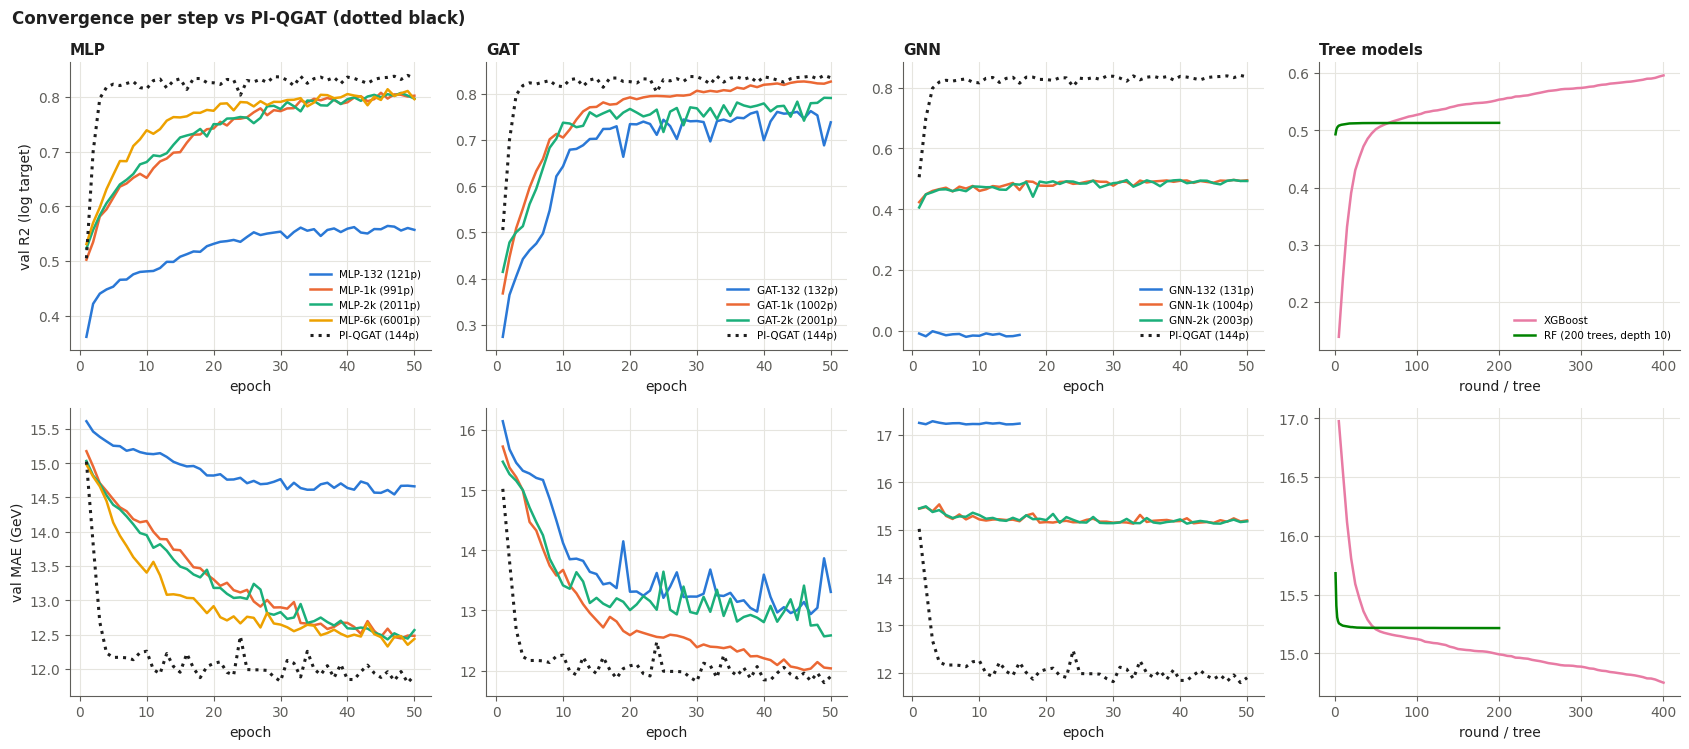

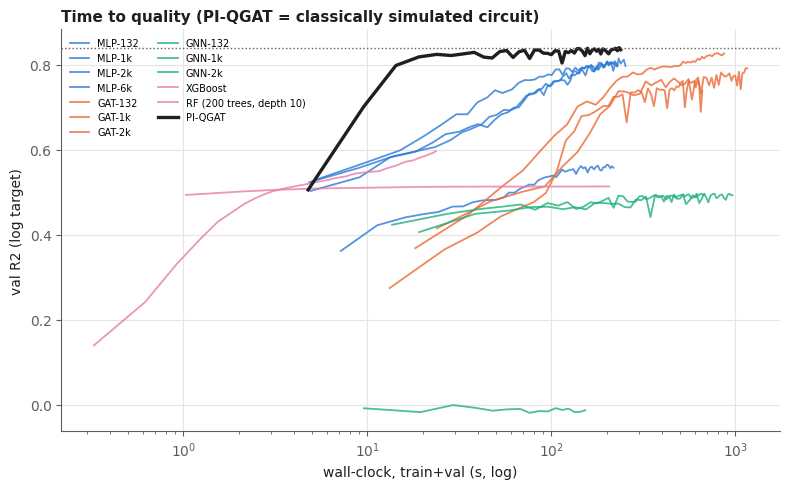

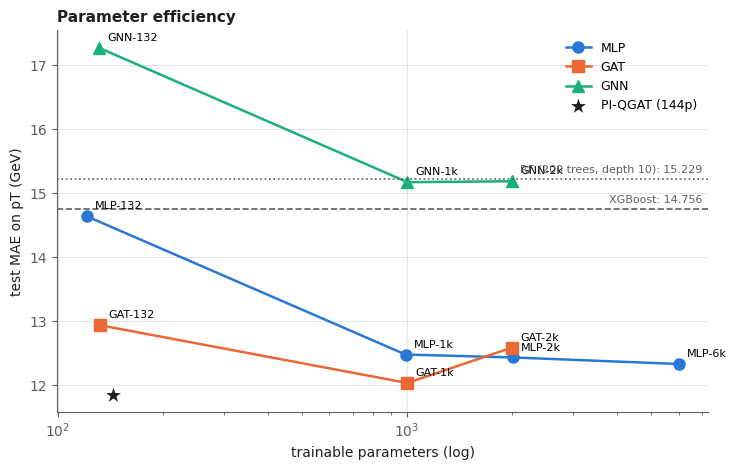


Saved to .


In [ ]:
"""
================================================================================
CELL — CLASSICAL BASELINES vs PI-QGAT (OLD-CELL architectures + protocol, same log format)
Classical models: plain PyTorch only (no JAX, no jit, no torch.compile).
Run AFTER Cell 1 (needs: X_*, phi_*, ba_*, y_*, pT_test, val_df, edge_recv/edge_send,
r_mean_d/r_std_d, Y_MEAN/Y_STD, PT_CLAMP_LO, PHI_IS_RADIANS, DEVICE, SEED, N_NODES, N_FEATS).

Kept exactly as the old cell:
  FlatMLP : Linear(28,h) -> ReLU -> Linear(h,1), raw log output, plain Adam (NO weight decay)
  PIGAT   : same 76-param PI-QGAT skeleton (node_proj, pair_proj, physics_prior, head),
            output = y_hat*Y_STD+Y_MEAN, Adam with L2 wd 3e-5
  loss    : SmoothL1(beta=1) on raw log(1+pT), LR 1e-3, batch 64, clip 1.0, no scheduler
  stop    : best-val checkpoint, improvement tol 1e-5, patience 12, max 50 epochs
  XGBoost : 400 est, depth 6, lr 0.05, subsample/colsample 0.8, early stop 30, raw log target
  RF      : 200 trees, depth 10, raw log target
  clamp   : lower-only at PT_CLAMP_LO; n_negative = expm1(pred) < PT_CLAMP_LO
Changed: param targets (84 -> 132 for the matched models) and added 1k variants.
Changed: reference model Q6 -> current PI-QGAT (144 params, values from the Cell 3 log, seed 42).
         The classical baselines are unchanged (same versions, same 132 / 1k / 2k / 6k targets).
================================================================================
"""
import os, math, time, random, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# ==============================================================================
# 0. CONFIG
# ==============================================================================
BASE_PARAMS    = 132         # param target of the small classical baselines (unchanged)
MODEL_PARAMS   = 144         # PI-QGAT (Cell 3) trainable parameters
N_SEEDS        = 1
EPOCHS         = 50
PATIENCE       = 12          # = Cell 2 / old cell. None -> always run all 50 epochs.
IMPROVE_TOL    = 1e-5
BATCH_SIZE     = 64
EVAL_BS        = 8192
LR             = 1e-3
CLASSICAL_WEIGHT_DECAY = 3e-5   # graph models only; FlatMLP has none (as old cell)
GRAD_CLIP_NORM = 1.0
SMOOTH_L1_BETA = 1.0
LAMBDA_PHYSICS = 0.1
BOUND_PHYSICS_PRIOR = True
PHYSICS_BOUND_SCALE = 6.0
STANDARDIZE_OUTPUT  = True      # graph models only (FlatMLP outputs raw log, as old cell)
D_NODE         = 4
N_EDGES        = N_NODES * (N_NODES - 1)
XGB_EVAL_EVERY = 5              # val curve resolution for XGBoost (1 = every round, slower)
TREE_PRINT_EVERY = 10
THR_R2LOG      = [0.50, 0.70, 0.80]
THR_MAE        = [13.0, 12.5, 12.2]
PT_EDGES       = [2, 4, 6, 10, 20, 50, 100, np.inf]
OUT_DIR        = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# (name, family, kind, target_params)
SPECS = [
    ("MLP-132",  "MLP", "flat",        BASE_PARAMS),
    ("MLP-1k",   "MLP", "flat",        1000),
    ("MLP-2k",   "MLP", "flat",        2000),
    ("MLP-6k",   "MLP", "flat",        6000),
    ("GAT-132",  "GAT", "gat_matched", BASE_PARAMS),   # exact 132 (fixed structure, see PIGAT)
    ("GAT-1k",   "GAT", "gat",         1000),
    ("GAT-2k",   "GAT", "gat",         2000),
    ("GNN-132",  "GNN", "gnn",         BASE_PARAMS),
    ("GNN-1k",   "GNN", "gnn",         1000),
    ("GNN-2k",   "GNN", "gnn",         2000),
]
RUN_XGB, RUN_RF = True, True

# ---- PI-QGAT reference: transcribed from the Cell 3 log (seed 42, 144 params) ---------------------------
MODEL_NAME = "PI-QGAT"
MODEL_VAL_LOSS = [0.1540,0.1007,0.0707,0.0640,0.0618,0.0623,0.0617,0.0612,0.0633,0.0637,
                  0.0596,0.0588,0.0630,0.0595,0.0585,0.0636,0.0591,0.0579,0.0600,0.0607,
                  0.0609,0.0587,0.0587,0.0669,0.0591,0.0597,0.0589,0.0594,0.0574,0.0571,
                  0.0597,0.0618,0.0573,0.0617,0.0589,0.0578,0.0591,0.0576,0.0601,0.0573,
                  0.0576,0.0591,0.0603,0.0585,0.0577,0.0577,0.0571,0.0586,0.0566,0.0579]
MODEL_VAL_R2 = [0.5052,0.7002,0.7977,0.8179,0.8238,0.8212,0.8251,0.8286,0.8175,0.8153,
                0.8303,0.8331,0.8167,0.8300,0.8336,0.8141,0.8341,0.8341,0.8267,0.8263,
                0.8233,0.8324,0.8316,0.8036,0.8306,0.8280,0.8327,0.8269,0.8374,0.8370,
                0.8309,0.8209,0.8382,0.8253,0.8338,0.8367,0.8313,0.8360,0.8249,0.8367,
                0.8343,0.8298,0.8252,0.8326,0.8353,0.8362,0.8383,0.8324,0.8398,0.8348]
MODEL_VAL_MAE = [15.023,13.826,12.681,12.231,12.167,12.169,12.161,12.134,12.237,12.258,
                 11.990,11.929,12.224,12.036,11.951,12.222,12.010,11.872,12.033,12.079,
                 12.103,11.949,11.910,12.477,11.990,11.986,11.986,11.977,11.884,11.820,
                 12.123,12.083,11.882,12.256,12.000,11.914,12.047,11.871,12.067,11.846,
                 11.844,11.959,12.054,11.939,11.875,11.958,11.828,11.961,11.799,11.903]
MODEL_TOTAL_S = 238.0             # Cell 3 total time (train + val, 50 epochs)
MODEL_MSE_PT = 16094.447          # Cell 3 test MSE on pT (GeV^2) -> gives R2_pT on the same test set
MODEL_TEST = {"MAE_pT": 11.8517, "RMSE_pT": 126.8639,
              "R2_pT": 1.0 - MODEL_MSE_PT / float(np.var(np.asarray(pT_test, dtype=np.float64))),
              "MAE_log": 0.21427, "RMSE_log": 0.37629, "R2_log": 0.83952}
MODEL_N_NEGATIVE = 824            # Cell 3 "predictions clamped at pT floor"
MODEL_CURVE = pd.DataFrame({
    "Model": MODEL_NAME, "Family": "Quantum", "Seed": SEED, "unit": "epoch",
    "step": np.arange(1, 51), "val_loss": MODEL_VAL_LOSS, "val_R2_log": MODEL_VAL_R2,
    "val_MAE_pT": MODEL_VAL_MAE, "time_s": np.arange(1, 51) * MODEL_TOTAL_S / 50})
_mb = int(np.argmin(MODEL_VAL_LOSS))
MODEL_R2_BEST, MODEL_MAE_BEST = MODEL_VAL_R2[_mb], MODEL_VAL_MAE[_mb]

print("Backend: plain PyTorch", torch.__version__, "(no jit) | Device:", DEVICE, "|", MODEL_NAME, MODEL_PARAMS, "params",
      "| small-baseline target:", BASE_PARAMS, "| SmoothL1(raw log) | bs", BATCH_SIZE, "| lr", LR)

# ==============================================================================
# 1. TENSORS
# ==============================================================================
def to_dev(a):
    return torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)

Xd = {"train": to_dev(X_train), "val": to_dev(X_val), "test": to_dev(X_test)}
Pd = {"train": to_dev(phi_train), "val": to_dev(phi_val), "test": to_dev(phi_test)}
Bd = {"train": to_dev(ba_train),  "val": to_dev(ba_val),  "test": to_dev(ba_test)}
ytr_d = to_dev(y_train)
pT_val = val_df["pT"].values.astype(np.float32)
Xflat = {k: v.reshape(len(v), -1) for k, v in
         {"train": X_train, "val": X_val, "test": X_test}.items()}

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

# ==============================================================================
# 2. MODELS  (old-cell definitions)
# ==============================================================================
class FlatMLP(nn.Module):
    """Old cell: 28 flat features -> hidden -> ReLU -> 1, raw log output, no graph."""
    def __init__(self, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(N_NODES * N_FEATS, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x, phi_raw=None, ba_raw=None):
        return self.net(x.reshape(x.shape[0], -1)).squeeze(-1)

class PIGAT(nn.Module):
    """
    Old-cell PI-QGAT skeleton (node_proj, pair_proj, physics_prior, regression_head = 76 params).
      gat_matched : attn_vec(4)+msg_bias(4)+bias-free msg_net 4->6->4 (48) = 56 extra -> 132 exactly
      gat         : attn_vec(4) + msg_net(4->h->4)                          -> 84 + 9h
      gnn         : NO attention (uniform mean over 3 neighbours), no physics prior,
                    msg_net(4->h->4): 72 + 9h + 4
    """
    def __init__(self, style, msg_hidden=4, lambda_physics=LAMBDA_PHYSICS):
        super().__init__()
        assert style in ("gat_matched", "gat", "gnn")
        self.style = style
        self.lambda_physics = lambda_physics
        self.node_proj = nn.Linear(N_FEATS, D_NODE)
        self.pair_proj = nn.Linear(2 * D_NODE, D_NODE)
        self.regression_head = nn.Linear(D_NODE, 1)
        self.register_buffer("edge_recv", edge_recv.clone())
        self.register_buffer("edge_send", edge_send.clone())
        if style != "gnn":
            self.physics_prior = nn.Linear(2, 1)
        if style == "gat_matched":
            self.attn_vec = nn.Parameter(torch.randn(D_NODE) * 0.5)
            self.msg_bias = nn.Parameter(torch.zeros(D_NODE))
            self.msg_net = nn.Sequential(nn.Linear(D_NODE, 6, bias=False), nn.Tanh(),
                                         nn.Linear(6, D_NODE, bias=False))
        elif style == "gat":
            self.attn_vec = nn.Parameter(torch.randn(D_NODE) * 0.5)
            self.msg_net = nn.Sequential(nn.Linear(D_NODE, msg_hidden), nn.Tanh(),
                                         nn.Linear(msg_hidden, D_NODE))
        else:
            self.msg_net = nn.Sequential(nn.Linear(D_NODE, msg_hidden), nn.Tanh(),
                                         nn.Linear(msg_hidden, D_NODE))

    def forward(self, x, phi_raw, ba_raw):
        B = x.shape[0]; n_in = N_NODES - 1
        h = self.node_proj(x)
        recv, send = self.edge_recv, self.edge_send
        h_i, h_j = h[:, recv, :], h[:, send, :]
        u = self.pair_proj(torch.cat([h_i, h_j], dim=-1))
        if self.style == "gnn":
            msg = h_j + self.msg_net(u)
            m = msg.view(B, N_NODES, n_in, D_NODE).mean(dim=2)
        else:
            phi_i, phi_j = phi_raw[:, recv], phi_raw[:, send]
            ba_i, ba_j = ba_raw[:, recv], ba_raw[:, send]
            dphi = (torch.atan2(torch.sin(phi_j - phi_i), torch.cos(phi_j - phi_i))
                    if PHI_IS_RADIANS else phi_j - phi_i)
            r = torch.stack([(ba_j - ba_i).abs(), dphi.abs()], dim=-1)
            P = self.physics_prior((r - r_mean_d) / r_std_d).squeeze(-1)
            if BOUND_PHYSICS_PRIOR:
                P = PHYSICS_BOUND_SCALE * torch.tanh(P / PHYSICS_BOUND_SCALE)
            q_att = F.leaky_relu((u * self.attn_vec).sum(-1), negative_slope=0.2)
            q = (self.msg_bias + self.msg_net(u)) if self.style == "gat_matched" else self.msg_net(u)
            alpha = torch.softmax((q_att + self.lambda_physics * P).view(B, N_NODES, n_in), dim=-1)
            m = (alpha.unsqueeze(-1) * (h_j + q).view(B, N_NODES, n_in, D_NODE)).sum(dim=2)
        y_hat = self.regression_head((h + m).mean(dim=1)).squeeze(-1)
        return y_hat * Y_STD + Y_MEAN if STANDARDIZE_OUTPUT else y_hat

def build_model(kind, h):
    if kind == "flat":        return FlatMLP(h)
    if kind == "gat_matched": return PIGAT("gat_matched")
    return PIGAT(kind, msg_hidden=h)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def match_hidden(kind, target, max_h=2000):
    """gat_matched is fixed (no search). Others: hidden width with params closest to target."""
    if kind == "gat_matched":
        return 6, count_params(build_model(kind, 6))
    best = None
    for h in range(1, max_h + 1):
        p = count_params(build_model(kind, h))
        if best is None or abs(p - target) < abs(best[1] - target):
            best = (h, p)
        if p > 2 * target:
            break
    return best

# ==============================================================================
# 3. METRICS / LOGGING (same format as before; all predictions are on raw log(1+pT))
# ==============================================================================
def to_pT(y_log):
    return np.clip(np.expm1(y_log), PT_CLAMP_LO, None)        # lower clip only

def huber_np(pl, y):
    a = np.abs(pl - y.astype(np.float64))
    return float(np.mean(np.where(a < SMOOTH_L1_BETA, 0.5 * a ** 2 / SMOOTH_L1_BETA, a - 0.5 * SMOOTH_L1_BETA)))

def val_record(pred_log):
    pl = pred_log.astype(np.float64); pT = to_pT(pl)
    return {"val_loss": huber_np(pl, y_val),
            "val_R2_log": r2_score(y_val, pl), "val_MAE_log": mean_absolute_error(y_val, pl),
            "val_MAE_pT": mean_absolute_error(pT_val, pT),
            "val_RMSE_pT": math.sqrt(mean_squared_error(pT_val, pT)),
            "val_R2_pT": r2_score(pT_val, pT)}

def log_step(name, unit, k, K, rec):
    print(f"[{name}] {unit} {k:>3d}/{K}  val loss {rec['val_loss']:.4f}  "
          f"val R2_log {rec['val_R2_log']:.4f}  val MAE(GeV) {rec['val_MAE_pT']:.3f}  "
          f"{rec['step_time_s']:.1f}s/{unit}")

def bin_table(pt_true, pt_pred):
    resid = pt_pred - pt_true
    rel = resid / np.maximum(pt_true, 1e-8)
    se = resid ** 2; tot = se.sum(); rows = []
    for lo, hi in zip(PT_EDGES[:-1], PT_EDGES[1:]):
        m = (pt_true >= lo) & (pt_true < hi)
        if not m.any():
            continue
        lab = f"[{lo:g}, {hi:g})" if np.isfinite(hi) else f"[{lo:g}, inf)"
        rows.append({"pT bin (GeV)": lab, "N": int(m.sum()), "% of set": 100 * m.mean(),
                     "MAE": np.abs(resid[m]).mean(), "med|rel|": np.median(np.abs(rel[m])),
                     "bias": rel[m].mean(), "resolution": rel[m].std(),
                     "R2 (bin)": r2_score(pt_true[m], pt_pred[m]) if m.sum() > 1 else np.nan,
                     "% of SSE": 100 * se[m].sum() / tot})
    return pd.DataFrame(rows)

def fmt_bins(df):
    d = df.copy()
    d["% of set"] = d["% of set"].map(lambda v: f"{v:.1f}%")
    d["% of SSE"] = d["% of SSE"].map(lambda v: f"{v:.1f}%")
    for c in ["MAE", "med|rel|", "bias", "resolution", "R2 (bin)"]:
        d[c] = d[c].map(lambda v: f"{v:.3f}")
    return d

def test_eval(pred_log):
    pl = pred_log.astype(np.float64); pT = to_pT(pl)
    return {"MAE_pT": mean_absolute_error(pT_test, pT),
            "RMSE_pT": math.sqrt(mean_squared_error(pT_test, pT)),
            "R2_pT": r2_score(pT_test, pT),
            "MAE_log": mean_absolute_error(y_test, pl),
            "RMSE_log": math.sqrt(mean_squared_error(y_test, pl)),
            "R2_log": r2_score(y_test, pl),
            "MedRelErr": float(np.median(np.abs(pT - pT_test) / pT_test)),
            "n_negative": int((np.expm1(pl) < PT_CLAMP_LO).sum()),
            "bins": bin_table(pT_test.astype(np.float64), pT)}

def report(name, unit, params_txt, hist, tm, train_time):
    print(f"\n[{name}] done: {train_time:.1f}s total, {len(hist)} {unit}s")
    print(f"\n[{name} (test set)]")
    print(fmt_bins(tm["bins"]).to_string(index=False))
    print("\n" + "=" * 110)
    row = pd.DataFrame([{"variant": name, "params": params_txt, "val loss": hist["val_loss"].min(),
                         "R2_log": tm["R2_log"], "MAE_log": tm["MAE_log"], "MAE(GeV)": tm["MAE_pT"],
                         "R2_pT": tm["R2_pT"], "epochs": len(hist), "secs": train_time}])
    print(row.to_string(index=False, formatters={
        "val loss": "{:.4f}".format, "R2_log": "{:.4f}".format, "MAE_log": "{:.4f}".format,
        "MAE(GeV)": "{:.3f}".format, "R2_pT": "{:.4f}".format, "secs": "{:.1f}".format}))
    print(f"\nTest-set RMSE(GeV): {tm['RMSE_pT']:.3f}   RMSE_log: {tm['RMSE_log']:.4f}   "
          f"n_negative(pre-clamp): {tm['n_negative']}")

# ==============================================================================
# 4. TRAINING  (old-cell loop: Adam, SmoothL1 on raw log, clip, best-val, patience)
# ==============================================================================
@torch.no_grad()
def predict_log(model, split):
    model.eval()
    X, P, Bv = Xd[split], Pd[split], Bd[split]
    return torch.cat([model(X[s:s + EVAL_BS], P[s:s + EVAL_BS], Bv[s:s + EVAL_BS])
                      for s in range(0, len(X), EVAL_BS)]).float().cpu().numpy()

def train_nn(model, name, n_params, flat):
    if flat:   # old train_flat_mlp: plain Adam, no weight decay
        opt = torch.optim.Adam(model.parameters(), lr=LR)
    else:      # old make_optimizer: Adam, L2 3e-5
        opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=CLASSICAL_WEIGHT_DECAY)
    n = len(Xd["train"]); nb = math.ceil(n / BATCH_SIZE)
    print("\n" + "=" * 80)
    print(f"Training {name}  |  {n_params} params  |  {nb} batches/epoch  |  {EPOCHS} epochs max "
          f"(patience {PATIENCE})")
    print("=" * 80)
    hist, best, best_state, bad, cum, cum_train = [], float("inf"), None, 0, 0.0, 0.0
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(n, device=DEVICE); run = torch.zeros((), device=DEVICE)
        sync(); t0 = time.perf_counter()
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]
            pred = model(Xd["train"][b], Pd["train"][b], Bd["train"][b])
            loss = F.smooth_l1_loss(pred, ytr_d[b], beta=SMOOTH_L1_BETA)
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            opt.step()
            run += loss.detach() * len(b)
        sync(); t_train = time.perf_counter() - t0
        rec = val_record(predict_log(model, "val"))
        sync(); dt = time.perf_counter() - t0               # train + val, like Cell 2 s/epoch
        cum += dt; cum_train += t_train
        rec.update({"step": ep, "train_loss": float(run.item()) / n, "step_time_s": dt,
                    "time_s": cum, "train_only_s": cum_train})
        hist.append(rec); log_step(name, "epoch", ep, EPOCHS, rec)
        if rec["val_loss"] < best - IMPROVE_TOL:
            best, bad = rec["val_loss"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if PATIENCE is not None and bad >= PATIENCE:
                print(f"[{name}] early stop at epoch {ep}")
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(hist), cum

def run_xgb(seed):
    import xgboost as xgb
    class _T(xgb.callback.TrainingCallback):
        def __init__(self): self.t, self.t0 = [], None
        def before_training(self, model): self.t0 = time.perf_counter(); return model
        def after_iteration(self, model, epoch, evals_log):
            self.t.append(time.perf_counter() - self.t0); return False
    cb = _T()
    m = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, objective="reg:squarederror", random_state=seed,
                         early_stopping_rounds=30, n_jobs=-1, callbacks=[cb])
    m.fit(Xflat["train"], y_train, eval_set=[(Xflat["val"], y_val)], verbose=False)
    booster = m.get_booster(); R = len(cb.t)
    dval = xgb.DMatrix(Xflat["val"])
    steps = sorted(set(list(range(XGB_EVAL_EVERY, R + 1, XGB_EVAL_EVERY)) + [R]))
    print("\n" + "=" * 80)
    print(f"Training XGBoost (old config)  |  {R} rounds trained (best {m.best_iteration + 1})  "
          f"|  val evaluated every {XGB_EVAL_EVERY} rounds")
    print("=" * 80)
    hist, prev_t = [], 0.0
    for k in steps:
        rec = val_record(booster.predict(dval, iteration_range=(0, k)))
        rec.update({"step": k, "train_loss": np.nan, "time_s": cb.t[k - 1], "train_only_s": cb.t[k - 1],
                    "step_time_s": cb.t[k - 1] - prev_t}); prev_t = cb.t[k - 1]
        hist.append(rec)
        if k % TREE_PRINT_EVERY == 0 or k == R: log_step("XGBoost", "round", k, R, rec)
    t1 = time.perf_counter(); pred = m.predict(Xflat["test"]); infer = time.perf_counter() - t1
    nodes = len(booster.trees_to_dataframe())
    return pd.DataFrame(hist), pred, cb.t[-1], nodes, infer

def run_rf(seed):
    T = 200
    rf = RandomForestRegressor(n_estimators=T, max_depth=10, random_state=seed, n_jobs=-1)
    t0 = time.perf_counter(); rf.fit(Xflat["train"], y_train); train_time = time.perf_counter() - t0
    Xv = Xflat["val"].astype(np.float32)
    print("\n" + "=" * 80)
    print(f"Training RF (old config: {T} trees, depth 10)  |  fit {train_time:.1f}s "
          f"(per-tree time = total/T, trees fit in parallel)")
    print("=" * 80)
    hist, run_sum = [], np.zeros(len(Xv), dtype=np.float64)
    for k, est in enumerate(rf.estimators_, 1):
        run_sum += est.predict(Xv)
        rec = val_record(run_sum / k)
        rec.update({"step": k, "train_loss": np.nan, "time_s": train_time * k / T,
                    "train_only_s": train_time * k / T, "step_time_s": train_time / T})
        hist.append(rec)
        if k % TREE_PRINT_EVERY == 0 or k == T: log_step("RF", "tree", k, T, rec)
    t1 = time.perf_counter(); pred = rf.predict(Xflat["test"]); infer = time.perf_counter() - t1
    nodes = int(sum(t.tree_.node_count for t in rf.estimators_))
    return pd.DataFrame(hist), pred, train_time, nodes, infer

# ==============================================================================
# 5. CONVERGENCE
# ==============================================================================
def conv_row(name, hist):
    v = hist["val_loss"].values; best = np.nanmin(v)
    masks = {"loss<=best+5%": v <= best * 1.05, "loss<=best+1%": v <= best * 1.01}
    for t in THR_R2LOG: masks[f"R2log>={t:.2f}"] = hist["val_R2_log"].values >= t
    for t in THR_MAE:   masks[f"MAE<={t:g}"]     = hist["val_MAE_pT"].values <= t
    masks["R2log>=PIQGATbest"] = hist["val_R2_log"].values >= MODEL_R2_BEST
    masks["MAE<=PIQGATbest"]   = hist["val_MAE_pT"].values <= MODEL_MAE_BEST
    row = {"Model": name, "best_step": int(hist["step"].values[np.nanargmin(v)])}
    for key, m in masks.items():
        idx = np.flatnonzero(m)
        row[f"step|{key}"] = int(hist["step"].values[idx[0]]) if idx.size else np.nan
        row[f"secs|{key}"] = float(hist["time_s"].values[idx[0]]) if idx.size else np.nan
    return row

# ==============================================================================
# 6. RUN
# ==============================================================================
print("\nParameter matching (small-baseline target = %d params; %s = %d params):" % (BASE_PARAMS, MODEL_NAME, MODEL_PARAMS))
ARCH = {}
for name, fam, kind, target in SPECS:
    h, p = match_hidden(kind, target)
    if kind == "gat_matched":
        assert p == BASE_PARAMS, f"GAT-132 has {p} params, expected {BASE_PARAMS}"
    ARCH[name] = (fam, kind, h, p, target)
    print(f"  {name:<8s} target {target:>5d} -> {kind:<11s} hidden {h:>4d} -> {p:>5d} params "
          f"({100 * (p - target) / target:+.1f}%)")

summ_rows, curve_frames, bin_frames, conv_rows = [], [], [], []

def finish(name, fam, seed, unit, params, nodes, hist, tm, train_time, infer_s, params_txt):
    hist = hist.assign(Model=name, Family=fam, Seed=seed, unit=unit)
    curve_frames.append(hist)
    bin_frames.append(tm["bins"].assign(Model=name, Seed=seed))
    conv_rows.append({**conv_row(name, hist), "Seed": seed})
    summ_rows.append({"Model": name, "Family": fam, "Seed": seed, "Params": params, "TreeNodes": nodes,
                      "best_val_loss": hist["val_loss"].min(),
                      **{k: tm[k] for k in ["MAE_pT", "RMSE_pT", "R2_pT", "MAE_log", "RMSE_log",
                                            "R2_log", "MedRelErr", "n_negative"]},
                      "epochs_run": int(hist["step"].max()), "train_time_s": train_time,
                      "infer_ms_per_1k": 1e6 * infer_s / len(pT_test), "step_unit": unit})
    report(name, unit, params_txt, hist, tm, train_time)

for si in range(N_SEEDS):
    seed = SEED + si
    print(f"\n\n#################### seed {seed} ####################")
    for name, (fam, kind, h, n_params, target) in ARCH.items():
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        model = build_model(kind, h).to(DEVICE)
        hist, tt = train_nn(model, name, n_params, flat=(kind == "flat"))
        sync(); t0 = time.perf_counter(); pred = predict_log(model, "test"); sync()
        infer = time.perf_counter() - t0
        finish(name, fam, seed, "epoch", n_params, np.nan, hist, test_eval(pred), tt, infer, str(n_params))
        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    if RUN_XGB:
        try:
            hist, pred, tt, nodes, infer = run_xgb(seed)
            finish("XGBoost", "Tree", seed, "round", np.nan, nodes, hist, test_eval(pred), tt, infer,
                   f"n/a ({nodes} nodes)")
        except ImportError:
            print("xgboost missing -> skipped")
    if RUN_RF:
        hist, pred, tt, nodes, infer = run_rf(seed)
        finish("RF (200 trees, depth 10)", "Tree", seed, "tree", np.nan, nodes, hist, test_eval(pred),
               tt, infer, f"n/a ({nodes} nodes)")

# ==============================================================================
# 7. TABLES
# ==============================================================================
per_seed = pd.DataFrame(summ_rows)
curves_df = pd.concat(curve_frames + [MODEL_CURVE], ignore_index=True)
bins_df = pd.concat(bin_frames, ignore_index=True)
conv_df = pd.DataFrame(conv_rows)

num = [c for c in per_seed.columns if c not in ("Model", "Family", "Seed", "step_unit")]
summary = per_seed.groupby(["Model", "Family", "step_unit"], sort=False)[num].mean().reset_index()
if N_SEEDS > 1:
    sd = per_seed.groupby(["Model", "Family", "step_unit"], sort=False)[
        ["MAE_pT", "MAE_log", "R2_log", "R2_pT"]].std().reset_index(drop=True)
    for c in sd.columns: summary[c + "_std"] = sd[c].values
model_row = {"Model": MODEL_NAME, "Family": "Quantum", "step_unit": "epoch", "Params": MODEL_PARAMS,
             "TreeNodes": np.nan, "best_val_loss": min(MODEL_VAL_LOSS), **MODEL_TEST,
             "epochs_run": 50, "train_time_s": MODEL_TOTAL_S, "n_negative": MODEL_N_NEGATIVE}
summary = pd.concat([pd.DataFrame([model_row]), summary], ignore_index=True)
conv_model = {**conv_row(MODEL_NAME, MODEL_CURVE), "Seed": SEED}
conv_all = pd.concat([pd.DataFrame([conv_model]),
                      conv_df.groupby("Model", sort=False).mean(numeric_only=True).reset_index()],
                     ignore_index=True)

summary.to_csv(os.path.join(OUT_DIR, "baseline_summary.csv"), index=False)
per_seed.to_csv(os.path.join(OUT_DIR, "baseline_per_seed.csv"), index=False)
curves_df.to_csv(os.path.join(OUT_DIR, "baseline_epoch_metrics.csv"), index=False)
bins_df.to_csv(os.path.join(OUT_DIR, "baseline_test_bins.csv"), index=False)
conv_all.to_csv(os.path.join(OUT_DIR, "baseline_convergence.csv"), index=False)

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 60)
print("\n\n" + "=" * 120 + "\nTEST SUMMARY (pT in GeV)\n" + "=" * 120)
cols = ["Model", "Params", "TreeNodes", "best_val_loss", "MAE_pT", "RMSE_pT", "R2_pT", "MAE_log",
        "RMSE_log", "R2_log", "MedRelErr", "n_negative", "epochs_run", "train_time_s", "infer_ms_per_1k"]
print(summary[[c for c in cols if c in summary.columns]].to_string(index=False, na_rep="-",
      float_format=lambda v: f"{v:.4f}"))

keys = [c[5:] for c in conv_all.columns if c.startswith("step|")]
print("\n" + "=" * 120 + "\nCONVERGENCE — first STEP (epoch/round/tree) hitting each threshold ('-' = never)\n" + "=" * 120)
print(conv_all[["Model", "best_step"] + [f"step|{k}" for k in keys]].rename(
      columns=lambda c: c.replace("step|", "")).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.0f}"))
print("\n" + "=" * 120 + "\nCONVERGENCE — cumulative wall-clock SECONDS (train+val) to first hit\n" + "=" * 120)
print(conv_all[["Model"] + [f"secs|{k}" for k in keys]].rename(
      columns=lambda c: c.replace("secs|", "")).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.1f}"))

# ==============================================================================
# 8. FIGURES
# ==============================================================================
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
INK, INK2, GRID = "#1f1f1f", "#5f5e5a", "#e6e5df"
SIZE_COLOR = {BASE_PARAMS: C[0], 1000: C[1], 2000: C[2], 6000: C[3]}
FAM_STYLE = {"MLP": (C[0], "o"), "GAT": (C[1], "s"), "GNN": (C[2], "^")}
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "legend.frameon": False})
def style_ax(ax):
    ax.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)

cv = curves_df[curves_df["Seed"] == SEED]
mc = cv[cv["Model"] == MODEL_NAME]
panels = [("MLP", ["MLP"]), ("GAT", ["GAT"]), ("GNN", ["GNN"]), ("Tree models", ["Tree"])]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
for row_i, (ycol, ylab) in enumerate([("val_R2_log", "val R2 (log target)"), ("val_MAE_pT", "val MAE (GeV)")]):
    for ax, (title, fams) in zip(axes[row_i], panels):
        tc = iter([C[4], C[5]])
        for name, g in cv[cv["Family"].isin(fams)].groupby("Model", sort=False):
            color = next(tc) if title == "Tree models" else SIZE_COLOR.get(ARCH[name][4], C[6])
            lab = f"{name} ({ARCH[name][3]}p)" if name in ARCH else name
            ax.plot(g["step"], g[ycol], color=color, lw=1.8, label=lab)
        if title != "Tree models":
            ax.plot(mc["step"], mc[ycol], color=INK, ls=":", lw=2.2, label=f"{MODEL_NAME} ({MODEL_PARAMS}p)")
        ax.set_title(title if row_i == 0 else "", loc="left", color=INK)
        ax.set_xlabel("round / tree" if title == "Tree models" else "epoch"); style_ax(ax)
        if row_i == 0: ax.legend(fontsize=7.5, loc="lower right")
    axes[row_i][0].set_ylabel(ylab)
fig.suptitle(f"Convergence per step vs {MODEL_NAME} (dotted black)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_convergence.png"), dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "fig_convergence.pdf"), bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name, g in cv.groupby("Model", sort=False):
    fam = g["Family"].iloc[0]
    color = INK if fam == "Quantum" else FAM_STYLE.get(fam, (C[4], ""))[0]
    ax.plot(g["time_s"], g["val_R2_log"], color=color, lw=2.4 if fam == "Quantum" else 1.3,
            alpha=1 if fam == "Quantum" else 0.8, label=name)
ax.axhline(MODEL_R2_BEST, color=INK2, ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("wall-clock, train+val (s, log)"); ax.set_ylabel("val R2 (log target)")
ax.set_title(f"Time to quality ({MODEL_NAME} = classically simulated circuit)", loc="left", color=INK)
style_ax(ax); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_time_to_quality.png"), dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "fig_time_to_quality.pdf"), bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for fam, (color, mk) in FAM_STYLE.items():
    g = summary[summary["Family"] == fam].sort_values("Params")
    if g.empty: continue
    ax.plot(g["Params"], g["MAE_pT"], color=color, marker=mk, ms=8, lw=1.8, label=fam)
    for _, r in g.iterrows():
        ax.annotate(r["Model"], (r["Params"], r["MAE_pT"]), xytext=(6, 5), textcoords="offset points", fontsize=8)
ax.scatter([MODEL_PARAMS], [MODEL_TEST["MAE_pT"]], marker="*", s=260, color=INK, zorder=5,
           edgecolor="white", linewidth=1.5, label=f"{MODEL_NAME} ({MODEL_PARAMS}p)")
for (_, r), ls in zip(summary[summary["Family"] == "Tree"].iterrows(), ["--", ":"]):
    ax.axhline(r["MAE_pT"], color=INK2, ls=ls, lw=1.2)
    ax.annotate(f"{r['Model']}: {r['MAE_pT']:.3f}", xy=(1.0, r["MAE_pT"]), xycoords=("axes fraction", "data"),
                xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=8, color=INK2)
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (log)"); ax.set_ylabel("test MAE on pT (GeV)")
ax.set_title("Parameter efficiency", loc="left", color=INK); style_ax(ax); ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_param_efficiency.png"), dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "fig_param_efficiency.pdf"), bbox_inches="tight"); plt.show()
print("\nSaved to", OUT_DIR)

In [ ]:
"""
================================================================================
CELL 3b — PLAIN GNN BASELINE, ONE HIDDEN LAYER (node features only), same log format, compared to PI-QGAT
Run AFTER Cell 1. Needs: X_*, y_*, pT_test, val_df, PT_CLAMP_LO, DEVICE, SEED, N_NODES, N_FEATS.

Architecture:
  1 x GraphSAGE-style layer on the fully connected 4-node graph
      h' = ReLU( W_self h_i + W_nb mean_{j != i} h_j )
  -> mean pool over nodes -> Linear(w, 1) -> raw log(1+pT)
  Params = 16w + 1
Protocol = old FlatMLP baseline: plain Adam (no weight decay), SmoothL1(beta=1) on raw log,
  LR 1e-3, batch 64, grad clip 1.0, patience 12, tol 1e-5, max 50 epochs, lower-only pT clamp.
Plain PyTorch (no JAX, no jit). Reference = current PI-QGAT (144 params, Cell 3 log, seed 42) instead of Q6.
================================================================================
"""
import os, math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------- config ----------------
TARGETS       = [("GNN-132", 132), ("GNN-1k", 1000), ("GNN-2k", 2000)]
EPOCHS, PATIENCE, IMPROVE_TOL = 50, 12, 1e-5
BATCH_SIZE, EVAL_BS, LR, CLIP = 64, 8192, 1e-3, 1.0
BETA = 1.0
THR_R2LOG = [0.50, 0.70, 0.80]
THR_MAE   = [13.0, 12.5, 12.2]
PT_EDGES  = [2, 4, 6, 10, 20, 50, 100, np.inf]
OUT_DIR   = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
# ---- PI-QGAT reference: transcribed from the Cell 3 log (seed 42) ----
MODEL_NAME   = "PI-QGAT"
MODEL_PARAMS = 144
MODEL_MSE_PT = 16094.447          # Cell 3 test MSE on pT (GeV^2) -> gives R2_pT on the same test set
MODEL_TEST   = {"MAE_pT": 11.8517, "RMSE_pT": 126.8639,
                "R2_pT": 1.0 - MODEL_MSE_PT / float(np.var(np.asarray(pT_test, dtype=np.float64))),
                "MAE_log": 0.21427, "RMSE_log": 0.37629, "R2_log": 0.83952}

# ---------------- data ----------------
def to_dev(a): return torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)
Xd = {"train": to_dev(X_train), "val": to_dev(X_val), "test": to_dev(X_test)}
ytr_d = to_dev(y_train)
pT_val = val_df["pT"].values.astype(np.float32)
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

# ---------------- model ----------------
class SAGELayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__()
        self.self_lin = nn.Linear(din, dout)
        self.nb_lin = nn.Linear(din, dout, bias=False)
    def forward(self, h):                                       # h: (B, N_NODES, d)
        nb = (h.sum(1, keepdim=True) - h) / (h.shape[1] - 1)    # mean over the other 3 nodes
        return self.self_lin(h) + self.nb_lin(nb)

class PlainGNN(nn.Module):
    def __init__(self, w):
        super().__init__()
        self.l1 = SAGELayer(N_FEATS, w)
        self.head = nn.Linear(w, 1)
    def forward(self, x):
        h = F.relu(self.l1(x))
        return self.head(h.mean(1)).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters())
def match_width(target):
    best = None
    for w in range(1, 2000):
        p = n_params(PlainGNN(w))
        if best is None or abs(p - target) < abs(best[1] - target): best = (w, p)
        if p > 2 * target: break
    return best

# ---------------- metrics ----------------
def to_pT(yl): return np.clip(np.expm1(yl), PT_CLAMP_LO, None)
def huber_np(pl, y):
    a = np.abs(pl - y.astype(np.float64))
    return float(np.mean(np.where(a < BETA, 0.5 * a**2 / BETA, a - 0.5 * BETA)))

@torch.no_grad()
def predict(model, split):
    model.eval(); X = Xd[split]
    return torch.cat([model(X[s:s+EVAL_BS]) for s in range(0, len(X), EVAL_BS)]).float().cpu().numpy().astype(np.float64)

def val_rec(pl):
    pT = to_pT(pl)
    return {"val_loss": huber_np(pl, y_val), "val_R2_log": r2_score(y_val, pl),
            "val_MAE_log": mean_absolute_error(y_val, pl),
            "val_MAE_pT": mean_absolute_error(pT_val, pT)}

def bin_table(pt, pp):
    resid = pp - pt; rel = resid / np.maximum(pt, 1e-8); se = resid**2; rows = []
    for lo, hi in zip(PT_EDGES[:-1], PT_EDGES[1:]):
        m = (pt >= lo) & (pt < hi)
        if not m.any(): continue
        rows.append({"pT bin (GeV)": f"[{lo:g}, {hi:g})" if np.isfinite(hi) else f"[{lo:g}, inf)",
                     "N": int(m.sum()), "% of set": f"{100*m.mean():.1f}%",
                     "MAE": f"{np.abs(resid[m]).mean():.3f}", "med|rel|": f"{np.median(np.abs(rel[m])):.3f}",
                     "bias": f"{rel[m].mean():.3f}", "resolution": f"{rel[m].std():.3f}",
                     "R2 (bin)": f"{r2_score(pt[m], pp[m]):.3f}" if m.sum() > 1 else "n/a",
                     "% of SSE": f"{100*se[m].sum()/se.sum():.1f}%"})
    return pd.DataFrame(rows)

# ---------------- training ----------------
def train(model, name, params):
    opt = torch.optim.Adam(model.parameters(), lr=LR)          # no weight decay, as FlatMLP
    n = len(Xd["train"]); nb = math.ceil(n / BATCH_SIZE)
    print("\n" + "="*80)
    print(f"Training {name}  |  {params} params  |  {nb} batches/epoch  |  {EPOCHS} epochs max (patience {PATIENCE})")
    print("="*80)
    hist, best, best_sd, bad, cum = [], float("inf"), None, 0, 0.0
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        sync(); t0 = time.perf_counter()
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s+BATCH_SIZE]
            loss = F.smooth_l1_loss(model(Xd["train"][b]), ytr_d[b], beta=BETA)
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
        rec = val_rec(predict(model, "val")); sync()
        dt = time.perf_counter() - t0; cum += dt
        rec.update({"step": ep, "time_s": cum}); hist.append(rec)
        print(f"[{name}] epoch {ep:3d}/{EPOCHS}  val loss {rec['val_loss']:.4f}  "
              f"val R2_log {rec['val_R2_log']:.4f}  val MAE(GeV) {rec['val_MAE_pT']:.3f}  {dt:.1f}s/epoch")
        if rec["val_loss"] < best - IMPROVE_TOL:
            best, bad = rec["val_loss"], 0
            best_sd = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"[{name}] early stop at epoch {ep}"); break
    model.load_state_dict(best_sd)
    return pd.DataFrame(hist), cum, best

def convergence(hist):
    row = {}
    v = hist["val_loss"].values
    masks = {"loss<=best+5%": v <= v.min()*1.05, "loss<=best+1%": v <= v.min()*1.01}
    for t in THR_R2LOG: masks[f"R2log>={t:.2f}"] = hist["val_R2_log"].values >= t
    for t in THR_MAE:   masks[f"MAE<={t:g}"] = hist["val_MAE_pT"].values <= t
    for k, m in masks.items():
        i = np.flatnonzero(m)
        row[k] = f"ep {int(hist['step'].values[i[0]])} ({hist['time_s'].values[i[0]]:.0f}s)" if i.size else "-"
    return row

# ---------------- run ----------------
print("Parameter matching (params = 16w + 1):")
plan = []
for name, tgt in TARGETS:
    w, p = match_width(tgt); plan.append((name, w, p, tgt))
    print(f"  {name:<8s} target {tgt:>5d} -> width {w:>3d} -> {p:>5d} params ({100*(p-tgt)/tgt:+.1f}%)")

summary, conv, curves = [], {}, []
for name, w, p, tgt in plan:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = PlainGNN(w).to(DEVICE)
    hist, secs, best = train(model, name, p)
    pl = predict(model, "test"); pT = to_pT(pl)
    tm = {"MAE_pT": mean_absolute_error(pT_test, pT), "RMSE_pT": math.sqrt(mean_squared_error(pT_test, pT)),
          "R2_pT": r2_score(pT_test, pT), "MAE_log": mean_absolute_error(y_test, pl),
          "RMSE_log": math.sqrt(mean_squared_error(y_test, pl)), "R2_log": r2_score(y_test, pl),
          "n_negative": int((np.expm1(pl) < PT_CLAMP_LO).sum())}
    print(f"\n[{name}] done: {secs:.1f}s total, {len(hist)} epochs")
    print(f"\n[{name} (test set)]")
    print(bin_table(pT_test.astype(np.float64), pT).to_string(index=False))
    print("\n" + "="*110)
    print(f"{'variant':<12}{'params':>8}{'val loss':>10}{'R2_log':>9}{'MAE_log':>9}{'MAE(GeV)':>10}{'R2_pT':>9}{'epochs':>8}{'secs':>9}")
    print(f"{name:<12}{p:>8}{best:>10.4f}{tm['R2_log']:>9.4f}{tm['MAE_log']:>9.4f}{tm['MAE_pT']:>10.3f}"
          f"{tm['R2_pT']:>9.4f}{len(hist):>8}{secs:>9.1f}")
    print(f"\nTest-set RMSE(GeV): {tm['RMSE_pT']:.3f}   RMSE_log: {tm['RMSE_log']:.4f}   "
          f"n_negative(pre-clamp): {tm['n_negative']}")
    summary.append({"Model": name, "Params": p, "best_val_loss": best, **tm,
                    "epochs": len(hist), "train_val_secs": secs})
    conv[name] = convergence(hist)
    curves.append(hist.assign(Model=name)); del model

sm = pd.concat([pd.DataFrame([{"Model": MODEL_NAME, "Params": MODEL_PARAMS, **MODEL_TEST}]),
                pd.DataFrame(summary)], ignore_index=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("\n\n" + "="*110 + f"\nTEST SUMMARY vs {MODEL_NAME}\n" + "="*110)
print(sm[["Model", "Params", "MAE_pT", "RMSE_pT", "R2_pT", "MAE_log", "RMSE_log", "R2_log"]]
      .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4f}"))
print("\nCONVERGENCE (first epoch and cumulative seconds to hit each threshold):")
print(pd.DataFrame(conv).T.to_string())

sm.to_csv(os.path.join(OUT_DIR, "gnn_plain_1layer_summary.csv"), index=False)
pd.concat(curves).to_csv(os.path.join(OUT_DIR, "gnn_plain_1layer_epoch_metrics.csv"), index=False)
print("\nSaved to", OUT_DIR)

Parameter matching (params = 16w + 1):
  GNN-132  target   132 -> width   8 ->   129 params (-2.3%)
  GNN-1k   target  1000 -> width  62 ->   993 params (-0.7%)
  GNN-2k   target  2000 -> width 125 ->  2001 params (+0.1%)

Training GNN-132  |  129 params  |  3686 batches/epoch  |  50 epochs max (patience 12)
[GNN-132] epoch   1/50  val loss 0.2516  val R2_log 0.1639  val MAE(GeV) 16.501  5.7s/epoch
[GNN-132] epoch   2/50  val loss 0.1926  val R2_log 0.3602  val MAE(GeV) 15.682  4.9s/epoch
[GNN-132] epoch   3/50  val loss 0.1689  val R2_log 0.4546  val MAE(GeV) 15.313  5.7s/epoch
[GNN-132] epoch   4/50  val loss 0.1622  val R2_log 0.4774  val MAE(GeV) 15.156  4.9s/epoch
[GNN-132] epoch   5/50  val loss 0.1530  val R2_log 0.5125  val MAE(GeV) 15.020  4.9s/epoch
[GNN-132] epoch   6/50  val loss 0.1494  val R2_log 0.5278  val MAE(GeV) 14.960  5.9s/epoch
[GNN-132] epoch   7/50  val loss 0.1469  val R2_log 0.5398  val MAE(GeV) 14.920  5.0s/epoch
[GNN-132] epoch   8/50  val loss 0.1449  val R

In [ ]:
"""
================================================================================
CELL 3c — PHYSICS-FREE GATv1 / GATv2 BASELINES (node features only), same log format, compared to PI-QGAT
Run AFTER Cell 1. Needs: X_*, y_*, pT_test, val_df, PT_CLAMP_LO, DEVICE, SEED, N_NODES, N_FEATS.

Standard single-head GAT layers on the fully connected 4-node graph (self-loops included,
as in PyG GATConv defaults). No physics prior, no edge features, no extra message net.
  GATv1 : e_ij = LeakyReLU( a_dst.Wh_i + a_src.Wh_j ),  out_i = sum_j softmax_j(e_ij) Wh_j + b
  GATv2 : e_ij = a . LeakyReLU( Wl h_i + Wr h_j ),      out_i = sum_j softmax_j(e_ij) Wr h_j + b
2 layers (ReLU) -> mean pool over nodes -> Linear(w,1) -> raw log(1+pT)
Protocol = plain GNN cell / old FlatMLP: plain Adam (no weight decay), SmoothL1(beta=1) on raw log,
LR 1e-3, batch 64, clip 1.0, patience 12, tol 1e-5, max 50 epochs, lower-only pT clamp.
Plain PyTorch (no JAX, no jit). Reference = current PI-QGAT (144 params, Cell 3 log, seed 42) instead of Q6.
================================================================================
"""
import os, math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------- config ----------------
TARGETS = [("GATv1-1k", "v1", 1000), ("GATv1-2k", "v1", 2000),
           ("GATv2-1k", "v2", 1000), ("GATv2-2k", "v2", 2000)]
EPOCHS, PATIENCE, IMPROVE_TOL = 50, 12, 1e-5
BATCH_SIZE, EVAL_BS, LR, CLIP = 64, 8192, 1e-3, 1.0
BETA = 1.0
THR_R2LOG = [0.50, 0.70, 0.80]
THR_MAE   = [13.0, 12.5, 12.2]
PT_EDGES  = [2, 4, 6, 10, 20, 50, 100, np.inf]
OUT_DIR   = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
# ---- PI-QGAT reference: transcribed from the Cell 3 log (seed 42) ----
MODEL_NAME   = "PI-QGAT"
MODEL_PARAMS = 144
MODEL_MSE_PT = 16094.447          # Cell 3 test MSE on pT (GeV^2) -> gives R2_pT on the same test set
MODEL_TEST   = {"MAE_pT": 11.8517, "RMSE_pT": 126.8639,
                "R2_pT": 1.0 - MODEL_MSE_PT / float(np.var(np.asarray(pT_test, dtype=np.float64))),
                "MAE_log": 0.21427, "RMSE_log": 0.37629, "R2_log": 0.83952}

# ---------------- data ----------------
def to_dev(a): return torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)
Xd = {"train": to_dev(X_train), "val": to_dev(X_val), "test": to_dev(X_test)}
ytr_d = to_dev(y_train)
pT_val = val_df["pT"].values.astype(np.float32)
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

# ---------------- model ----------------
class GATv1Layer(nn.Module):
    def __init__(self, din, dout):
        super().__init__()
        self.W = nn.Linear(din, dout, bias=False)
        self.a_src = nn.Parameter(torch.randn(dout) / math.sqrt(dout))
        self.a_dst = nn.Parameter(torch.randn(dout) / math.sqrt(dout))
        self.bias = nn.Parameter(torch.zeros(dout))
    def forward(self, h):                                    # (B, N, din)
        Wh = self.W(h)
        e = F.leaky_relu((Wh * self.a_dst).sum(-1).unsqueeze(2) +
                         (Wh * self.a_src).sum(-1).unsqueeze(1), 0.2)   # (B, i, j)
        return torch.softmax(e, dim=-1) @ Wh + self.bias

class GATv2Layer(nn.Module):
    def __init__(self, din, dout):
        super().__init__()
        self.Wl = nn.Linear(din, dout)                       # receiver
        self.Wr = nn.Linear(din, dout)                       # sender / message
        self.a = nn.Parameter(torch.randn(dout) / math.sqrt(dout))
        self.bias = nn.Parameter(torch.zeros(dout))
    def forward(self, h):
        hl, hr = self.Wl(h), self.Wr(h)
        e = (F.leaky_relu(hl.unsqueeze(2) + hr.unsqueeze(1), 0.2) * self.a).sum(-1)
        return torch.softmax(e, dim=-1) @ hr + self.bias

class PlainGAT(nn.Module):
    def __init__(self, kind, w):
        super().__init__()
        L = GATv1Layer if kind == "v1" else GATv2Layer
        self.l1, self.l2 = L(N_FEATS, w), L(w, w)
        self.head = nn.Linear(w, 1)
    def forward(self, x):
        h = F.relu(self.l1(x))
        h = F.relu(self.l2(h))
        return self.head(h.mean(1)).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters())
def match_width(kind, target):
    best = None
    for w in range(1, 1000):
        p = n_params(PlainGAT(kind, w))
        if best is None or abs(p - target) < abs(best[1] - target): best = (w, p)
        if p > 2 * target: break
    return best

# ---------------- metrics ----------------
def to_pT(yl): return np.clip(np.expm1(yl), PT_CLAMP_LO, None)
def huber_np(pl, y):
    a = np.abs(pl - y.astype(np.float64))
    return float(np.mean(np.where(a < BETA, 0.5 * a**2 / BETA, a - 0.5 * BETA)))

@torch.no_grad()
def predict(model, split):
    model.eval(); X = Xd[split]
    return torch.cat([model(X[s:s+EVAL_BS]) for s in range(0, len(X), EVAL_BS)]).float().cpu().numpy().astype(np.float64)

def val_rec(pl):
    pT = to_pT(pl)
    return {"val_loss": huber_np(pl, y_val), "val_R2_log": r2_score(y_val, pl),
            "val_MAE_log": mean_absolute_error(y_val, pl),
            "val_MAE_pT": mean_absolute_error(pT_val, pT)}

def bin_table(pt, pp):
    resid = pp - pt; rel = resid / np.maximum(pt, 1e-8); se = resid**2; rows = []
    for lo, hi in zip(PT_EDGES[:-1], PT_EDGES[1:]):
        m = (pt >= lo) & (pt < hi)
        if not m.any(): continue
        rows.append({"pT bin (GeV)": f"[{lo:g}, {hi:g})" if np.isfinite(hi) else f"[{lo:g}, inf)",
                     "N": int(m.sum()), "% of set": f"{100*m.mean():.1f}%",
                     "MAE": f"{np.abs(resid[m]).mean():.3f}", "med|rel|": f"{np.median(np.abs(rel[m])):.3f}",
                     "bias": f"{rel[m].mean():.3f}", "resolution": f"{rel[m].std():.3f}",
                     "R2 (bin)": f"{r2_score(pt[m], pp[m]):.3f}" if m.sum() > 1 else "n/a",
                     "% of SSE": f"{100*se[m].sum()/se.sum():.1f}%"})
    return pd.DataFrame(rows)

# ---------------- training ----------------
def train(model, name, params):
    opt = torch.optim.Adam(model.parameters(), lr=LR)          # no weight decay
    n = len(Xd["train"]); nb = math.ceil(n / BATCH_SIZE)
    print("\n" + "="*80)
    print(f"Training {name}  |  {params} params  |  {nb} batches/epoch  |  {EPOCHS} epochs max (patience {PATIENCE})")
    print("="*80)
    hist, best, best_sd, bad, cum = [], float("inf"), None, 0, 0.0
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        sync(); t0 = time.perf_counter()
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s+BATCH_SIZE]
            loss = F.smooth_l1_loss(model(Xd["train"][b]), ytr_d[b], beta=BETA)
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
        rec = val_rec(predict(model, "val")); sync()
        dt = time.perf_counter() - t0; cum += dt
        rec.update({"step": ep, "time_s": cum}); hist.append(rec)
        print(f"[{name}] epoch {ep:3d}/{EPOCHS}  val loss {rec['val_loss']:.4f}  "
              f"val R2_log {rec['val_R2_log']:.4f}  val MAE(GeV) {rec['val_MAE_pT']:.3f}  {dt:.1f}s/epoch")
        if rec["val_loss"] < best - IMPROVE_TOL:
            best, bad = rec["val_loss"], 0
            best_sd = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"[{name}] early stop at epoch {ep}"); break
    model.load_state_dict(best_sd)
    return pd.DataFrame(hist), cum, best

def convergence(hist):
    row = {}; v = hist["val_loss"].values
    masks = {"loss<=best+5%": v <= v.min()*1.05, "loss<=best+1%": v <= v.min()*1.01}
    for t in THR_R2LOG: masks[f"R2log>={t:.2f}"] = hist["val_R2_log"].values >= t
    for t in THR_MAE:   masks[f"MAE<={t:g}"] = hist["val_MAE_pT"].values <= t
    for k, m in masks.items():
        i = np.flatnonzero(m)
        row[k] = f"ep {int(hist['step'].values[i[0]])} ({hist['time_s'].values[i[0]]:.0f}s)" if i.size else "-"
    return row

# ---------------- run ----------------
print("Parameter matching:")
plan = []
for name, kind, tgt in TARGETS:
    w, p = match_width(kind, tgt); plan.append((name, kind, w, p, tgt))
    print(f"  {name:<9s} target {tgt:>5d} -> width {w:>3d} -> {p:>5d} params ({100*(p-tgt)/tgt:+.1f}%)")

summary, conv, curves = [], {}, []
for name, kind, w, p, tgt in plan:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = PlainGAT(kind, w).to(DEVICE)
    hist, secs, best = train(model, name, p)
    pl = predict(model, "test"); pT = to_pT(pl)
    tm = {"MAE_pT": mean_absolute_error(pT_test, pT), "RMSE_pT": math.sqrt(mean_squared_error(pT_test, pT)),
          "R2_pT": r2_score(pT_test, pT), "MAE_log": mean_absolute_error(y_test, pl),
          "RMSE_log": math.sqrt(mean_squared_error(y_test, pl)), "R2_log": r2_score(y_test, pl),
          "n_negative": int((np.expm1(pl) < PT_CLAMP_LO).sum())}
    print(f"\n[{name}] done: {secs:.1f}s total, {len(hist)} epochs")
    print(f"\n[{name} (test set)]")
    print(bin_table(pT_test.astype(np.float64), pT).to_string(index=False))
    print("\n" + "="*110)
    print(f"{'variant':<12}{'params':>8}{'val loss':>10}{'R2_log':>9}{'MAE_log':>9}{'MAE(GeV)':>10}{'R2_pT':>9}{'epochs':>8}{'secs':>9}")
    print(f"{name:<12}{p:>8}{best:>10.4f}{tm['R2_log']:>9.4f}{tm['MAE_log']:>9.4f}{tm['MAE_pT']:>10.3f}"
          f"{tm['R2_pT']:>9.4f}{len(hist):>8}{secs:>9.1f}")
    print(f"\nTest-set RMSE(GeV): {tm['RMSE_pT']:.3f}   RMSE_log: {tm['RMSE_log']:.4f}   "
          f"n_negative(pre-clamp): {tm['n_negative']}")
    summary.append({"Model": name, "Params": p, "best_val_loss": best, **tm,
                    "epochs": len(hist), "train_val_secs": secs})
    conv[name] = convergence(hist)
    curves.append(hist.assign(Model=name)); del model

sm = pd.concat([pd.DataFrame([{"Model": MODEL_NAME, "Params": MODEL_PARAMS, **MODEL_TEST}]),
                pd.DataFrame(summary)], ignore_index=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("\n\n" + "="*110 + f"\nTEST SUMMARY vs {MODEL_NAME}\n" + "="*110)
print(sm[["Model", "Params", "MAE_pT", "RMSE_pT", "R2_pT", "MAE_log", "RMSE_log", "R2_log"]]
      .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4f}"))
print("\nCONVERGENCE (first epoch and cumulative seconds to hit each threshold):")
print(pd.DataFrame(conv).T.to_string())

sm.to_csv(os.path.join(OUT_DIR, "gat_plain_summary.csv"), index=False)
pd.concat(curves).to_csv(os.path.join(OUT_DIR, "gat_plain_epoch_metrics.csv"), index=False)
print("\nSaved to", OUT_DIR)

Parameter matching:
  GATv1-1k  target  1000 -> width  25 ->   976 params (-2.4%)
  GATv1-2k  target  2000 -> width  38 ->  1977 params (-1.1%)
  GATv2-1k  target  1000 -> width  17 ->   970 params (-3.0%)
  GATv2-2k  target  2000 -> width  26 ->  1951 params (-2.5%)

Training GATv1-1k  |  976 params  |  3686 batches/epoch  |  50 epochs max (patience 12)
[GATv1-1k] epoch   1/50  val loss 0.1933  val R2_log 0.3753  val MAE(GeV) 15.635  21.0s/epoch
[GATv1-1k] epoch   2/50  val loss 0.1843  val R2_log 0.4164  val MAE(GeV) 15.588  12.0s/epoch
[GATv1-1k] epoch   3/50  val loss 0.1790  val R2_log 0.4206  val MAE(GeV) 15.408  11.9s/epoch
[GATv1-1k] epoch   4/50  val loss 0.1777  val R2_log 0.4237  val MAE(GeV) 15.361  11.5s/epoch
[GATv1-1k] epoch   5/50  val loss 0.1747  val R2_log 0.4356  val MAE(GeV) 15.331  11.5s/epoch
[GATv1-1k] epoch   6/50  val loss 0.1717  val R2_log 0.4485  val MAE(GeV) 15.297  11.9s/epoch
[GATv1-1k] epoch   7/50  val loss 0.1693  val R2_log 0.4508  val MAE(GeV) 15.21